# Notebook 02: Visualización exploratoria
**Proyecto final: emisiones de CO₂ per cápita (Our World in Data)** · Responsable: Julian

Este notebook usa los datos que dejó el notebook 01 (`../data/co2_limpio_2019.csv`) y el dataset completo para las series de tiempo.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

AZUL = "#2a6fbb"      # color principal de datos
GRIS = "#8a8f98"      # contexto / comparaciones
ROJO = "#c8452f"      # resaltar un caso o la recta del modelo
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10,
})

ANIO = 2019   # mismo año de análisis que el notebook 01

df = pd.read_csv("../data/owid-co2-data.csv")          # dataset completo (series de tiempo)
limpio = pd.read_csv("../data/co2_limpio_2019.csv")    # países con datos completos en ANIO (salida del notebook 01)
print(f"Dataset completo: {df.shape[0]:,} filas | Dataset limpio: {limpio.shape[0]} países")

Matplotlib is building the font cache; this may take a moment.


Dataset completo: 56,269 filas | Dataset limpio: 164 países


Antes de modelar, se visualizan los datos para entender qué patrones existen.

## 2.1 Evolución de las emisiones mundiales

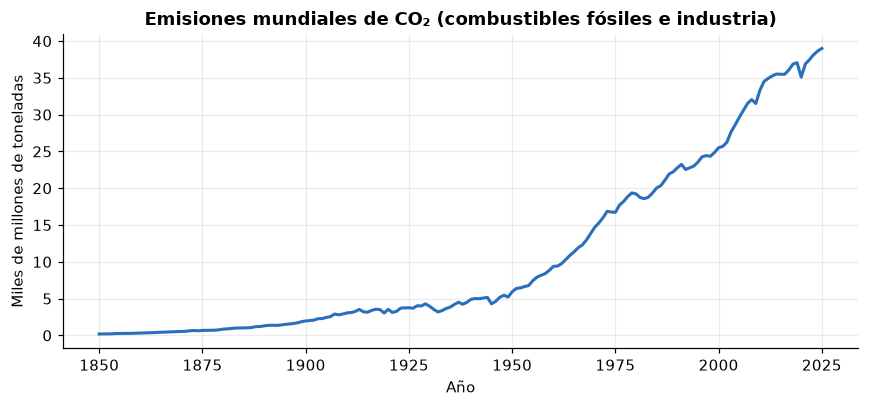

In [2]:
mundo = df[df["country"] == "World"].dropna(subset=["co2"])
mundo = mundo[mundo["year"] >= 1850]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(mundo["year"], mundo["co2"] / 1000, color=AZUL, lw=2)
ax.set_title("Emisiones mundiales de CO₂ (combustibles fósiles e industria)")
ax.set_ylabel("Miles de millones de toneladas")
ax.set_xlabel("Año")
plt.tight_layout(); plt.show()

## 2.2 ¿Quién emite más? Total frente a per cápita

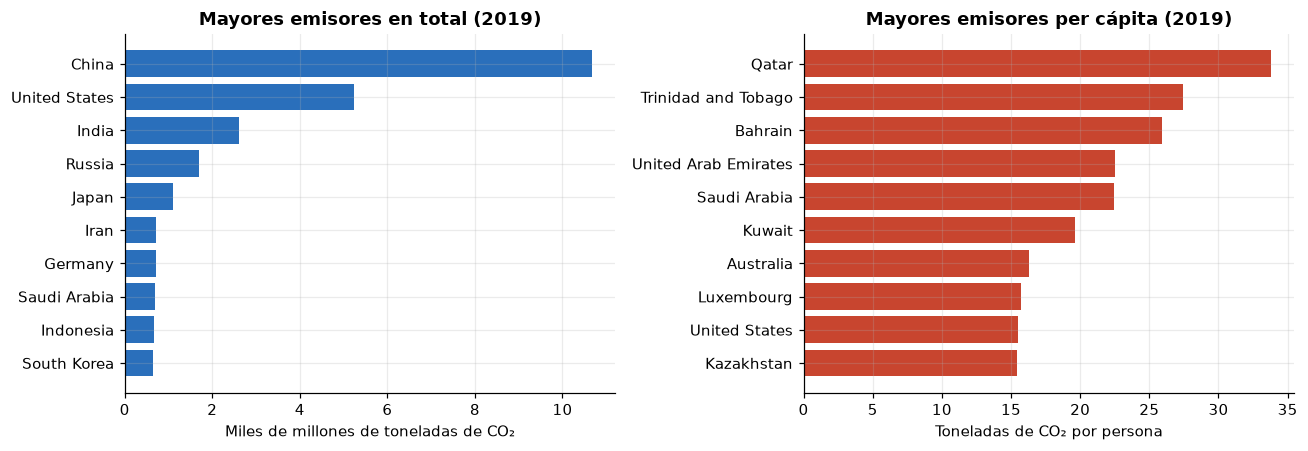

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

top_total = limpio.nlargest(10, "co2").sort_values("co2")
axes[0].barh(top_total["country"], top_total["co2"] / 1000, color=AZUL)
axes[0].set_title(f"Mayores emisores en total ({ANIO})")
axes[0].set_xlabel("Miles de millones de toneladas de CO₂")

top_pc = limpio.nlargest(10, "co2_per_capita").sort_values("co2_per_capita")
axes[1].barh(top_pc["country"], top_pc["co2_per_capita"], color=ROJO)
axes[1].set_title(f"Mayores emisores per cápita ({ANIO})")
axes[1].set_xlabel("Toneladas de CO₂ por persona")

plt.tight_layout(); plt.show()

**Lectura:** el ranking cambia por completo. En total emiten más los países grandes (China, Estados Unidos, India); por persona, destacan productores de petróleo y gas con poca población. Por eso el análisis se hace **per cápita**: permite comparar países de tamaños muy distintos.

## 2.3 Colombia frente a otros países de la región

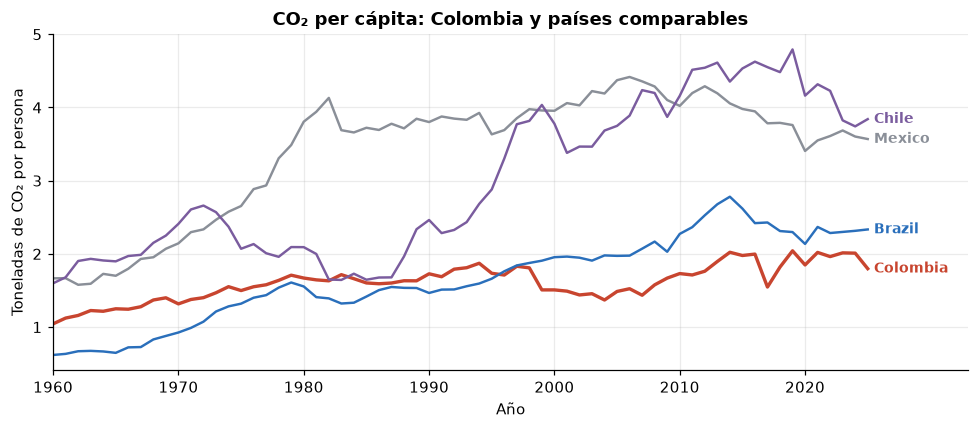

In [4]:
selec = {"Colombia": ROJO, "Brazil": AZUL, "Mexico": GRIS, "Chile": "#7a5c9e"}
serie = df[df["country"].isin(selec) & (df["year"] >= 1960)]

fig, ax = plt.subplots(figsize=(9, 4))
for pais, color in selec.items():
    s = serie[serie["country"] == pais]
    ax.plot(s["year"], s["co2_per_capita"], color=color, lw=2.2 if pais == "Colombia" else 1.6)
    ax.text(s["year"].iloc[-1] + 0.5, s["co2_per_capita"].iloc[-1], pais, color=color,
            va="center", fontsize=9, fontweight="bold")
ax.set_title("CO₂ per cápita: Colombia y países comparables")
ax.set_ylabel("Toneladas de CO₂ por persona")
ax.set_xlabel("Año")
ax.set_xlim(1960, serie["year"].max() + 8)
ax.set_xticks(range(1960, 2030, 10))
plt.tight_layout(); plt.show()

**Lectura:** Colombia emite por persona bastante menos que Chile y México y algo menos que Brasil, y su nivel se ha mantenido relativamente estable desde los años 90.

## 2.4 Distribución de las variables

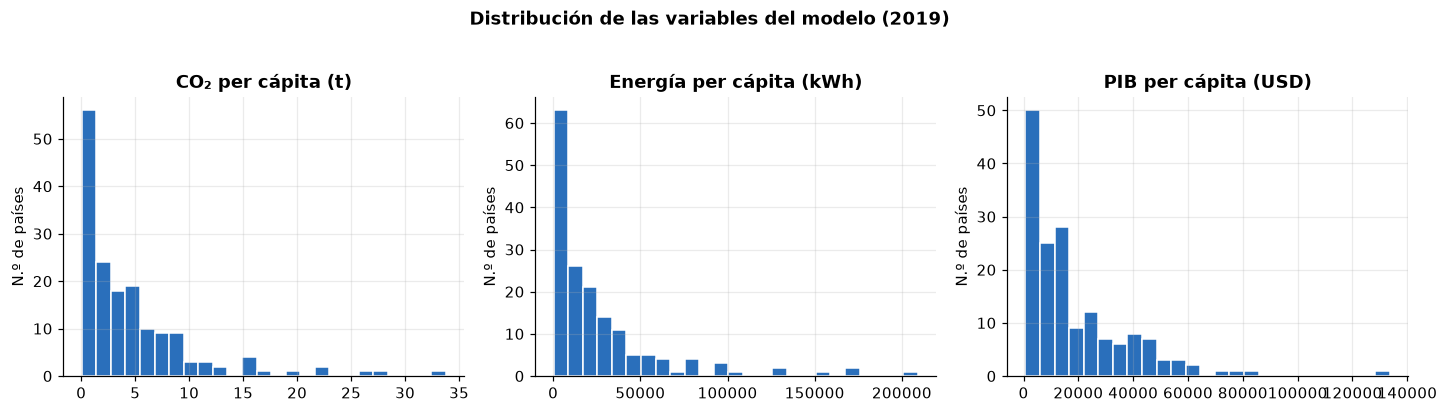

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, titulo in zip(axes, ["co2_per_capita", "energy_per_capita", "gdp_per_capita"],
                           ["CO₂ per cápita (t)", "Energía per cápita (kWh)", "PIB per cápita (USD)"]):
    ax.hist(limpio[col], bins=25, color=AZUL, edgecolor="white")
    ax.set_title(titulo); ax.set_ylabel("N.º de países")
plt.suptitle(f"Distribución de las variables del modelo ({ANIO})", y=1.03, fontweight="bold")
plt.tight_layout(); plt.show()

**Lectura:** las tres variables tienen **sesgo a la derecha**: muchos países con valores bajos y pocos con valores muy altos. Esto importa para la regresión, porque unos pocos países extremos pueden dominar el ajuste. Más adelante probamos una transformación logarítmica.

## 2.5 Relación entre las variables

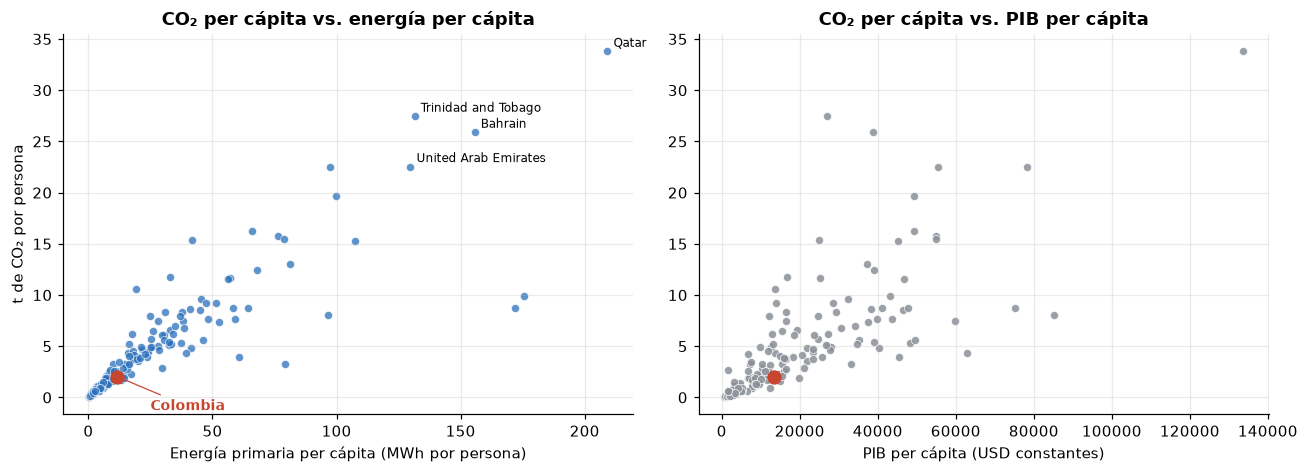

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

axes[0].scatter(limpio["energy_per_capita"] / 1000, limpio["co2_per_capita"], s=28, color=AZUL, alpha=0.75, edgecolor="white", lw=0.5)
axes[0].set_title("CO₂ per cápita vs. energía per cápita")
axes[0].set_xlabel("Energía primaria per cápita (MWh por persona)")
axes[0].set_ylabel("t de CO₂ por persona")

axes[1].scatter(limpio["gdp_per_capita"], limpio["co2_per_capita"], s=28, color=GRIS, alpha=0.85, edgecolor="white", lw=0.5)
axes[1].set_title("CO₂ per cápita vs. PIB per cápita")
axes[1].set_xlabel("PIB per cápita (USD constantes)")

# Etiquetar solo unos pocos países para no saturar el gráfico
for _, r in limpio.nlargest(4, "co2_per_capita").iterrows():
    axes[0].annotate(r["country"], (r["energy_per_capita"] / 1000, r["co2_per_capita"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
col = limpio[limpio["country"] == "Colombia"].iloc[0]
axes[0].scatter(col["energy_per_capita"] / 1000, col["co2_per_capita"], s=70, color=ROJO, zorder=3)
axes[0].annotate("Colombia", (col["energy_per_capita"] / 1000, col["co2_per_capita"]), fontsize=9, color=ROJO, fontweight="bold", xytext=(22, -22), textcoords="offset points",
                 arrowprops=dict(arrowstyle="-", color=ROJO, lw=0.8))
axes[1].scatter(col["gdp_per_capita"], col["co2_per_capita"], s=70, color=ROJO, zorder=3)
plt.tight_layout(); plt.show()

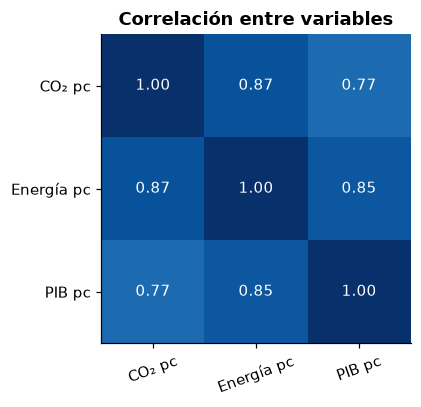

In [7]:
# Matriz de correlación (Pearson) entre las variables
etiquetas = {"co2_per_capita": "CO₂ pc", "energy_per_capita": "Energía pc", "gdp_per_capita": "PIB pc"}
corr = limpio[list(etiquetas)].rename(columns=etiquetas).corr()
fig, ax = plt.subplots(figsize=(4.6, 3.8))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(corr.columns, rotation=20)
ax.set_yticks(range(3)); ax.set_yticklabels(corr.columns)
ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if corr.iloc[i, j] > 0.6 else "black", fontsize=10)
ax.set_title("Correlación entre variables")
plt.tight_layout(); plt.show()

**Lectura:**
- La energía per cápita es la variable más relacionada con las emisiones (correlación 0,87), seguida del PIB per cápita (0,77).
- **Energía y PIB están muy correlacionados entre sí (0,85):** los países ricos consumen más energía. Por eso es esperable que, al usar ambas en un modelo, el PIB aporte poca información adicional.
- En los gráficos la nube de puntos se abre hacia la derecha: la dispersión crece con los valores altos. Además, hay países con mucha energía y emisiones relativamente bajas. Ambas cosas se revisan en el modelo.

### Mi lectura

- *Rankings:* Me llamó la atención que el ranking cambia según cómo se mida. En total lideran China, Estados Unidos e India, por su tamaño. Por habitante lideran países pequeños productores de petróleo y gas, como Qatar, Trinidad y Tobago y Baréin, con más de 25 t por persona.
- *Colombia:* Colombia emite cerca de 2 t por persona, por debajo de Brasil (~2,3) y bastante menos que México y Chile (~3,6 y ~3,8). Además, su nivel casi no ha cambiado desde los años 90, mientras que Chile y México crecieron mucho más.
- *Correlación y modelo:* La energía per cápita es la variable más ligada a las emisiones (0,87). Como energía y PIB también están muy correlacionados entre sí (0,85), el PIB probablemente aporte poco una vez que el modelo ya usa la energía. Por eso Ana debería tener cuidado al incluir ambas variables y probar la transformación logarítmica por el sesgo a la derecha.